In [1]:
# Step 1: Load the cleaned dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/netflix_cleaned.csv")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(8790, 14)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,September,125,min


In [2]:
# Step 2: Total number of Movies and TV Shows
counts = df["type"].value_counts()
print(counts)
print("Total titles:", len(df))

type
Movie      6126
TV Show    2664
Name: count, dtype: int64
Total titles: 8790


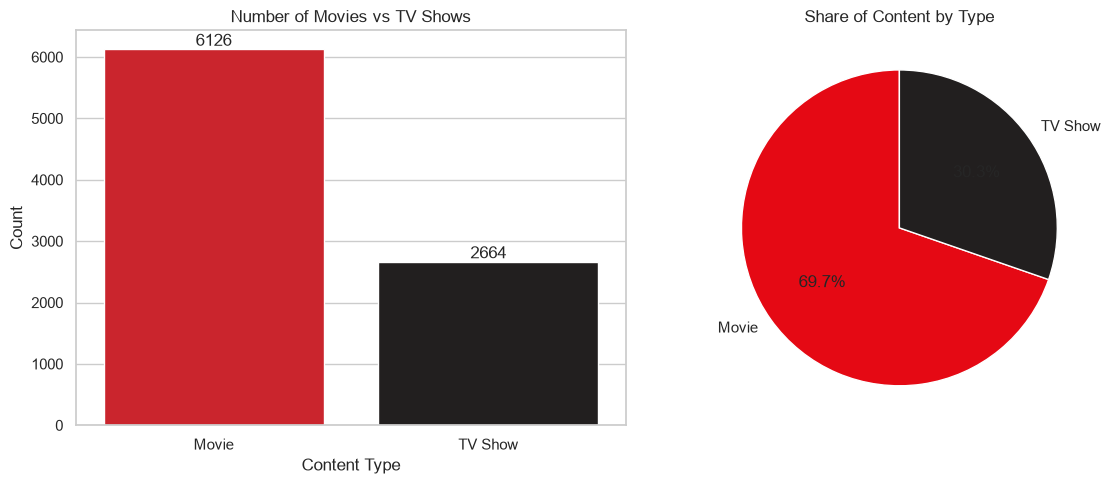

In [3]:
# Step 3: Visualize the content distribution
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="type", hue="type", palette=["#E50914", "#221F1F"],
              legend=False, ax=axes[0])
axes[0].set_title("Number of Movies vs TV Shows")
axes[0].set_xlabel("Content Type")
axes[0].set_ylabel("Count")
for container in axes[0].containers:
    axes[0].bar_label(container)

axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%",
            colors=["#E50914", "#221F1F"], startangle=90)
axes[1].set_title("Share of Content by Type")

plt.tight_layout()
plt.savefig("content_type_distribution.png", dpi=150)
plt.show()

type
Movie      69.7
TV Show    30.3
Name: proportion, dtype: float64
Movies per TV Show: 2.3


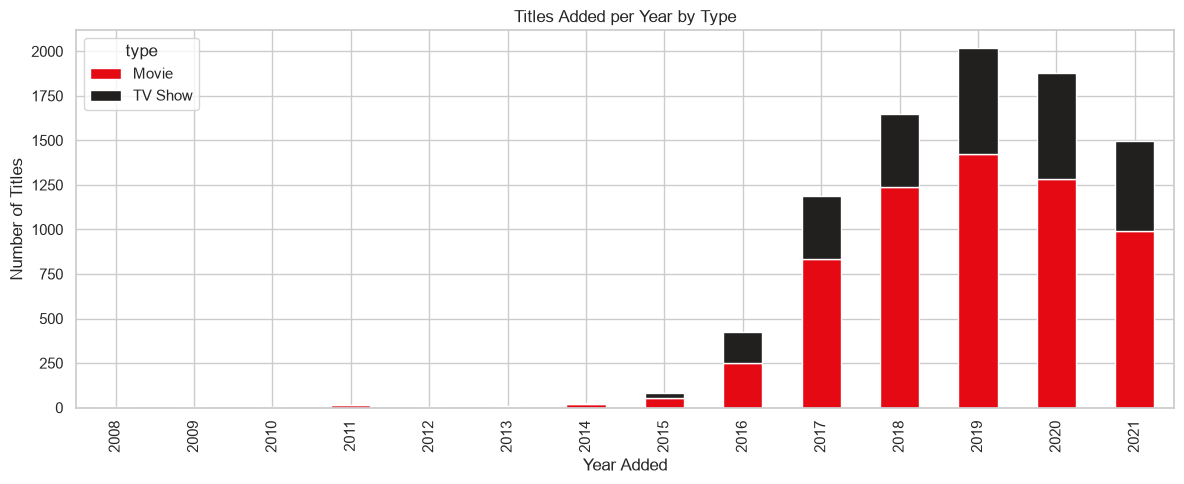

In [4]:
# Step 4: Compare content proportions
props = (df["type"].value_counts(normalize=True) * 100).round(1)
print(props)
print("Movies per TV Show:", round(counts["Movie"] / counts["TV Show"], 2))

# Bonus: how the mix changed by year added
by_year = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)
by_year.plot(kind="bar", stacked=True, figsize=(12, 5),
             color=["#E50914", "#221F1F"], title="Titles Added per Year by Type")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("content_type_by_year.png", dpi=150)
plt.show()

In [5]:
# Step 5: Key findings (edit the numbers after you see your output)
movie_pct = props["Movie"]
tv_pct = props["TV Show"]
print(f"Movies make up {movie_pct}% of the catalog and TV Shows {tv_pct}%.")

Movies make up 69.7% of the catalog and TV Shows 30.3%.


## Key Findings

- Movies make up 69.7% of the Netflix catalog (6,126 titles), while TV Shows make up 30.3% (2,664 titles). That is roughly 2.3 movies for every TV show.
- Content additions were very low before 2015, grew rapidly from 2016, and peaked in 2019.
- Movies outnumber TV Shows in every year shown, so the movie-heavy mix is consistent over time and not a one-year effect.
- Additions fell in 2020 and 2021. The 2021 figure is lower partly because the dataset covers only part of that year.
- **Insight:** The catalog leans heavily toward movies, which suits one-off viewing. Netflix could invest more in TV Shows, since multi-episode series keep viewers coming back and support long-term subscriptions.
